In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")


In [8]:

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())


Saving Unemployment in India.csv to Unemployment in India (3).csv
Dataset loaded successfully!
Shape: (768, 7)
           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                                     43.97  Rural  
4           12256762.0                      

In [9]:

df.columns = df.columns.str.strip()

print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Missing values:
Region                   

In [10]:

df = df.dropna().copy()

df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

df = df.dropna(subset=["Date"])

df["Region"] = df["Region"].astype(str).str.strip()
df["Month"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year

print("Cleaned dataset shape:", df.shape)
print(df.head())


Cleaned dataset shape: (740, 9)
           Region       Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh 2019-05-31   Monthly                             3.65   
1  Andhra Pradesh 2019-06-30   Monthly                             3.05   
2  Andhra Pradesh 2019-07-31   Monthly                             3.75   
3  Andhra Pradesh 2019-08-31   Monthly                             3.32   
4  Andhra Pradesh 2019-09-30   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  \
0          11999139.0                                    43.24  Rural   
1          11755881.0                                    42.05  Rural   
2          12086707.0                                    43.50  Rural   
3          12285693.0                                    43.97  Rural   
4          12256762.0                                    44.68  Rural   

       Month  Year  
0        May  2019  
1       June  2019  
2       July  2

In [11]:

print("Summary statistics:")
print(df.describe())

print("\nAverage unemployment rate:")
print(round(df["Estimated Unemployment Rate (%)"].mean(), 2), "%")

print("\nNumber of regions:", df["Region"].nunique())


Summary statistics:
                                Date  Estimated Unemployment Rate (%)  \
count                            740                       740.000000   
mean   2019-12-12 18:36:58.378378496                        11.787946   
min              2019-05-31 00:00:00                         0.000000   
25%              2019-08-31 00:00:00                         4.657500   
50%              2019-11-30 00:00:00                         8.350000   
75%              2020-03-31 00:00:00                        15.887500   
max              2020-06-30 00:00:00                        76.740000   
std                              NaN                        10.721298   

       Estimated Employed  Estimated Labour Participation Rate (%)  \
count        7.400000e+02                               740.000000   
mean         7.204460e+06                                42.630122   
min          4.942000e+04                                13.330000   
25%          1.190404e+06                 

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


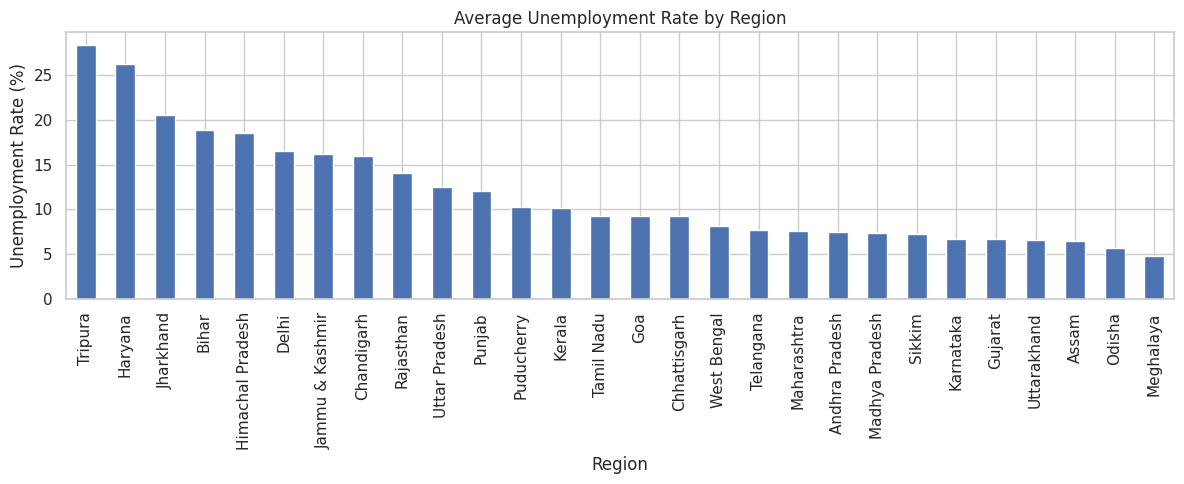

In [12]:

region_rate = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

print(region_rate)

region_rate.plot(kind="bar", figsize=(12, 5))
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


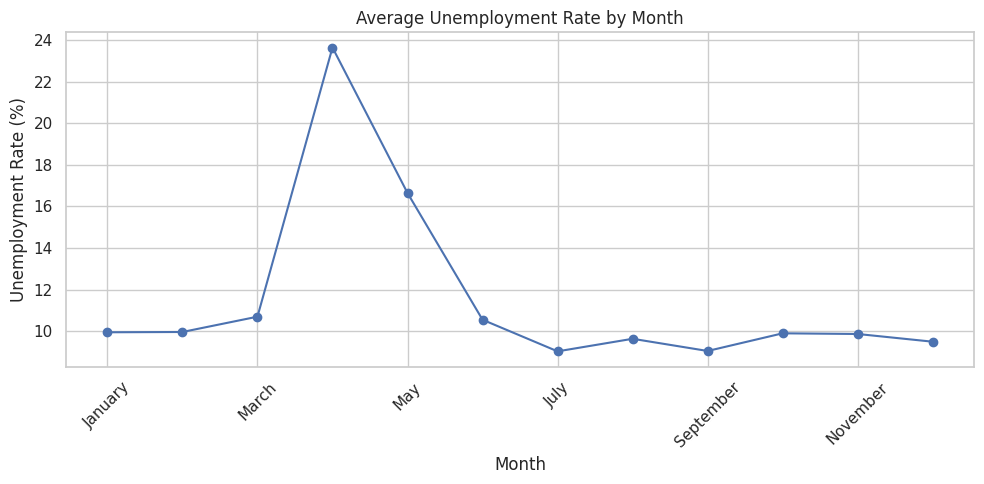

In [13]:

monthly_rate = df.groupby("Month")[
    "Estimated Unemployment Rate (%)"
].mean()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_rate = monthly_rate.reindex(month_order).dropna()

monthly_rate.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


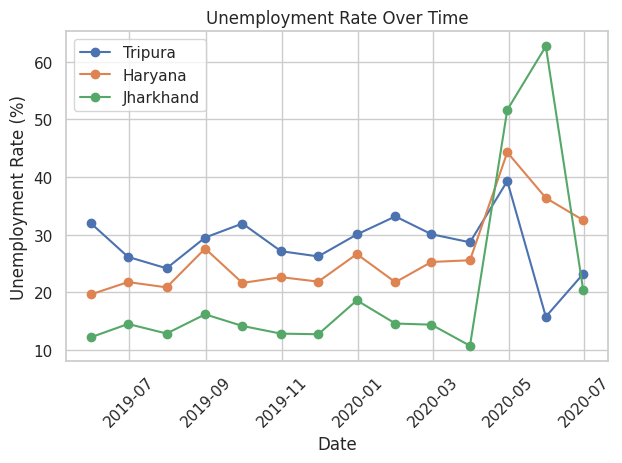

In [14]:

top_regions = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().nlargest(3).index

trend = df[df["Region"].isin(top_regions)].groupby(
    ["Date", "Region"]
)["Estimated Unemployment Rate (%)"].mean().reset_index()

for region in top_regions:
    data = trend[trend["Region"] == region]
    plt.plot(data["Date"], data["Estimated Unemployment Rate (%)"],
             marker="o", label=region)

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


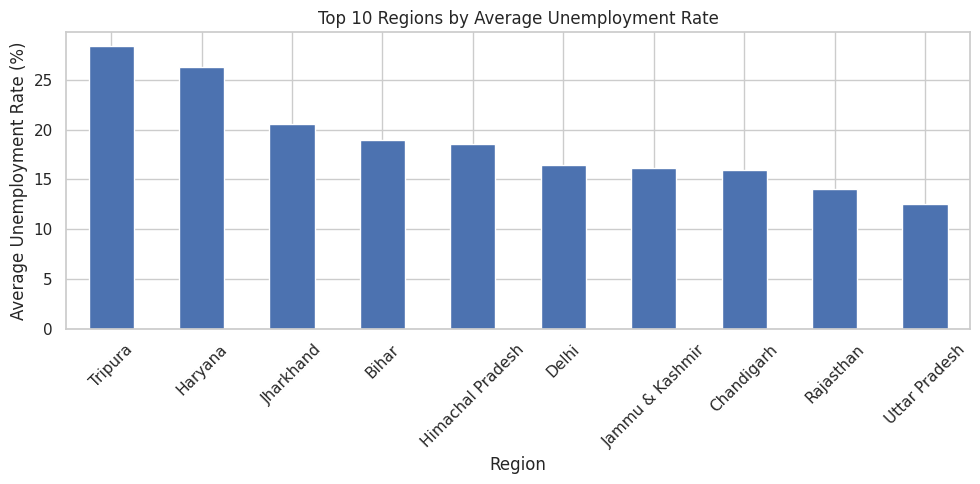

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


In [15]:

top10 = region_rate.head(10)

top10.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(top10)


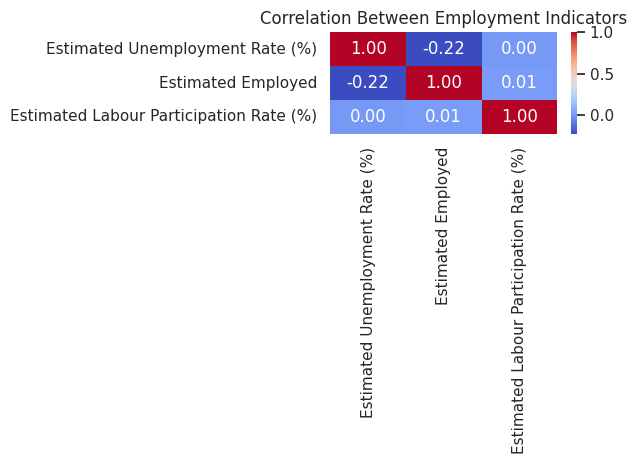

In [16]:

numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[numeric_cols].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()


Average unemployment before COVID: 9.51 %
Average unemployment during COVID: 17.77 %


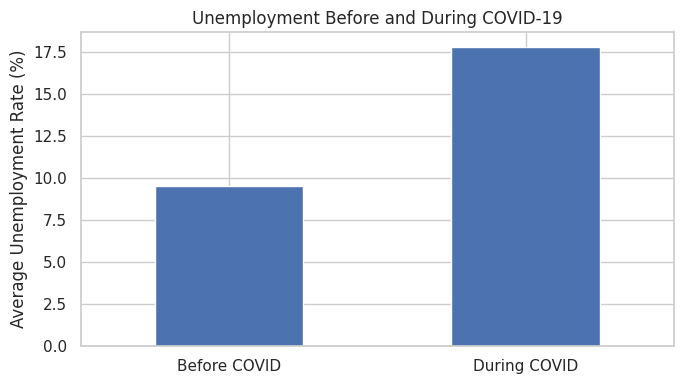

In [17]:

before_covid = df[df["Date"] < "2020-03-01"]
during_covid = df[df["Date"] >= "2020-03-01"]

before_avg = before_covid["Estimated Unemployment Rate (%)"].mean()
during_avg = during_covid["Estimated Unemployment Rate (%)"].mean()

print("Average unemployment before COVID:",
      round(before_avg, 2), "%")

print("Average unemployment during COVID:",
      round(during_avg, 2), "%")

comparison = pd.Series({
    "Before COVID": before_avg,
    "During COVID": during_avg
})

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Unemployment Before and During COVID-19")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

print("PROJECT CONCLUSION")

print("Highest average unemployment region:",
      region_rate.idxmax())

print("Highest monthly average unemployment:",
      monthly_rate.idxmax())

print("Before COVID average:", round(before_avg, 2), "%")
print("During COVID average:", round(during_avg, 2), "%")

if during_avg > before_avg:
    print("Unemployment was higher during the COVID period.")
else:
    print("Unemployment was not higher during the COVID period.")


PROJECT CONCLUSION
Highest average unemployment region: Tripura
Highest monthly average unemployment: April
Before COVID average: 9.51 %
During COVID average: 17.77 %
Unemployment was higher during the COVID period.
